In [13]:
# Add relevant Jupyter notebook extensions 


In [14]:
# You can double-check your Python path like this...
import sys

import uuv_mission.dynamic

# Simulate closed-loop
Simulating code with control functionality and plotting the result with random disturbances: 

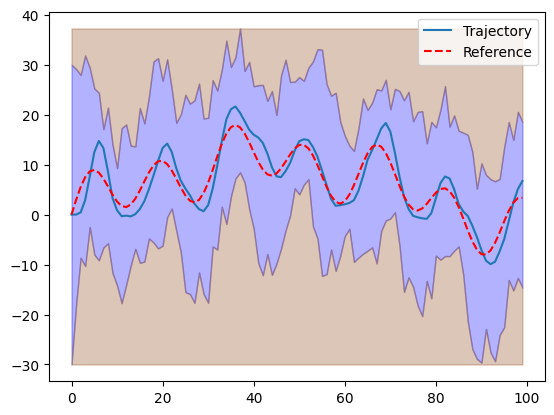

In [15]:
# Import relevant modules
import numpy as np
from uuv_mission.dynamic import Submarine, ClosedLoop, Mission
from uuv_mission.control import PDController

sub = uuv_mission.dynamic.Submarine()
# Instantiate your controller (depending on your implementation)
closed_loop = uuv_mission.dynamic.ClosedLoop(sub, PDController())
mission = uuv_mission.dynamic.Mission.from_csv(r"data\mission.csv") # You must implement this method in the Mission class

trajectory = closed_loop.simulate_with_random_disturbances(mission)
trajectory.plot_completed_mission(mission)

### Make Plot 
Add axis labels, another legend entry and title for clarity

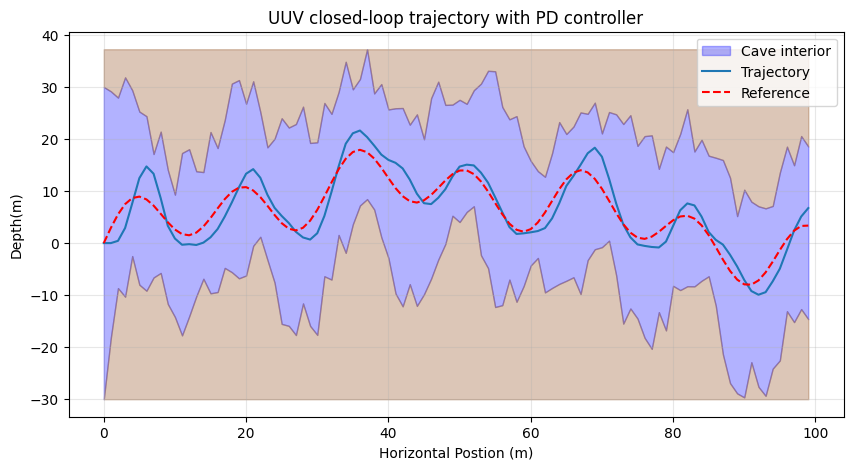

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(mission.reference))

plt.figure(figsize=(10, 5))
plt.fill_between(x, mission.cave_height, mission.cave_depth, color="blue", alpha=0.3, label="Cave interior")
plt.fill_between(x, mission.cave_depth, np.min(mission.cave_depth), color="saddlebrown", alpha=0.3)
plt.fill_between(x, np.max(mission.cave_height), mission.cave_height, color="saddlebrown", alpha=0.3)
plt.plot(trajectory.position[:, 0], trajectory.position[:, 1], label="Trajectory")
plt.plot(mission.reference, "r--", label="Reference")

plt.xlabel("Horizontal Postion (m)")
plt.ylabel("Depth(m)")
plt.title("UUV closed-loop trajectory with PD controller and random disturbances")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.savefig("trajectory.png", dpi=200, bbox_inches="tight")  # for the report appendix

plt.show()